In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# Step 1: Download data from yfinance
ticker = 'EURUSD=X'
period = '1mo'
interval = '5m'

data = yf.download(ticker, period=period, interval=interval)
data = data.droplevel(1,axis = 1)
data = data[['Open', 'High', 'Low', 'Close']].dropna()

# Check if enough data is available

data



[*********************100%***********************]  1 of 1 completed


Price,Open,High,Low,Close
Datetime,,,,
2025-03-25 08:35:00+00:00,1.079214,1.079447,1.079214,1.079331
2025-03-25 08:40:00+00:00,1.079447,1.079447,1.078981,1.078981
2025-03-25 08:45:00+00:00,1.079098,1.079098,1.078981,1.079098
2025-03-25 08:50:00+00:00,1.079214,1.079214,1.079098,1.079098
2025-03-25 08:55:00+00:00,1.079214,1.079447,1.079214,1.079331
...,...,...,...,...
2025-04-25 07:10:00+00:00,1.135460,1.136235,1.135460,1.136235
2025-04-25 07:15:00+00:00,1.136622,1.137010,1.136364,1.136751
2025-04-25 07:20:00+00:00,1.136622,1.136622,1.136105,1.136622


In [ ]:
data['pct_change'] = data['Close'].pct_change()
data.dropna(inplace=True)
data

Price,Open,High,Low,Close,pct_change
Datetime,,,,,
2025-03-25 08:40:00+00:00,1.079447,1.079447,1.078981,1.078981,-0.000324
2025-03-25 08:45:00+00:00,1.079098,1.079098,1.078981,1.079098,0.000108
2025-03-25 08:50:00+00:00,1.079214,1.079214,1.079098,1.079098,0.000000
2025-03-25 08:55:00+00:00,1.079214,1.079447,1.079214,1.079331,0.000216
2025-03-25 09:00:00+00:00,1.079331,1.079914,1.079331,1.079797,0.000432
...,...,...,...,...,...
2025-04-25 07:10:00+00:00,1.135460,1.136235,1.135460,1.136235,0.000909
2025-04-25 07:15:00+00:00,1.136622,1.137010,1.136364,1.136751,0.000455
2025-04-25 07:20:00+00:00,1.136622,1.136622,1.136105,1.136622,-0.000114


In [ ]:
data['Candle'] = np.where(data['Close'] > data['Open'], 'Green', 'Red')
data

Price,Open,High,Low,Close,pct_change,Candle
Datetime,,,,,,
2025-03-25 08:40:00+00:00,1.079447,1.079447,1.078981,1.078981,-0.000324,Red
2025-03-25 08:45:00+00:00,1.079098,1.079098,1.078981,1.079098,0.000108,Red
2025-03-25 08:50:00+00:00,1.079214,1.079214,1.079098,1.079098,0.000000,Red
2025-03-25 08:55:00+00:00,1.079214,1.079447,1.079214,1.079331,0.000216,Green
2025-03-25 09:00:00+00:00,1.079331,1.079914,1.079331,1.079797,0.000432,Green
...,...,...,...,...,...,...
2025-04-25 07:10:00+00:00,1.135460,1.136235,1.135460,1.136235,0.000909,Green
2025-04-25 07:15:00+00:00,1.136622,1.137010,1.136364,1.136751,0.000455,Green
2025-04-25 07:20:00+00:00,1.136622,1.136622,1.136105,1.136622,-0.000114,Red


In [ ]:
lookback = 500
for i in range(lookback, len(data)):
  sub_data = data[i-lookback:i]
  green_to_red = 0
  green_to_green = 0
  red_to_red = 0
  red_to_green = 0
  threshold = 0.51
  for j in range(1,len(sub_data)):
    if sub_data.iloc[j]['Candle'] == 'Green' and sub_data.iloc[j-1]['Candle'] == 'Red':
      green_to_red += 1
    elif sub_data.iloc[j]['Candle'] == 'Green' and sub_data.iloc[j-1]['Candle'] == 'Green':
      green_to_green += 1
    elif sub_data.iloc[j]['Candle'] == 'Red' and sub_data.iloc[j-1]['Candle'] == 'Red':
      red_to_red += 1
    elif sub_data.iloc[j]['Candle'] == 'Red' and sub_data.iloc[j-1]['Candle'] == 'Green':
      red_to_green += 1
  prob_green_to_red = (green_to_red/(green_to_red+green_to_green))
  prob_green_to_green = (green_to_green/(green_to_red+green_to_green))
  prob_red_to_red = (red_to_red/(red_to_red+red_to_green))
  prob_red_to_green = (red_to_green/(red_to_red+red_to_green))
  if data.iloc[i]['Candle'] == 'Green':
    if prob_green_to_red > threshold:
      signal = 1
    elif prob_green_to_green > threshold:
      signal = -1
    else: signal = 0
  elif data.iloc[i]['Candle'] == 'Red':
    if prob_red_to_green > threshold:
      signal = -1
    elif prob_red_to_red > threshold:
      signal = 1
    else: signal = 0
  data.loc[data.index[i], 'Signal'] = signal

data





Price,Open,High,Low,Close,pct_change,Candle,Signal,strat_ret
Datetime,,,,,,,,
2025-03-25 08:40:00+00:00,1.079447,1.079447,1.078981,1.078981,-0.000324,Red,NaN,NaN
2025-03-25 08:45:00+00:00,1.079098,1.079098,1.078981,1.079098,0.000108,Red,NaN,NaN
2025-03-25 08:50:00+00:00,1.079214,1.079214,1.079098,1.079098,0.000000,Red,NaN,NaN
2025-03-25 08:55:00+00:00,1.079214,1.079447,1.079214,1.079331,0.000216,Green,NaN,NaN
2025-03-25 09:00:00+00:00,1.079331,1.079914,1.079331,1.079797,0.000432,Green,NaN,NaN
...,...,...,...,...,...,...,...,...
2025-04-25 07:10:00+00:00,1.135460,1.136235,1.135460,1.136235,0.000909,Green,1.0,-0.000909
2025-04-25 07:15:00+00:00,1.136622,1.137010,1.136364,1.136751,0.000455,Green,1.0,-0.000455
2025-04-25 07:20:00+00:00,1.136622,1.136622,1.136105,1.136622,-0.000114,Red,1.0,0.000114


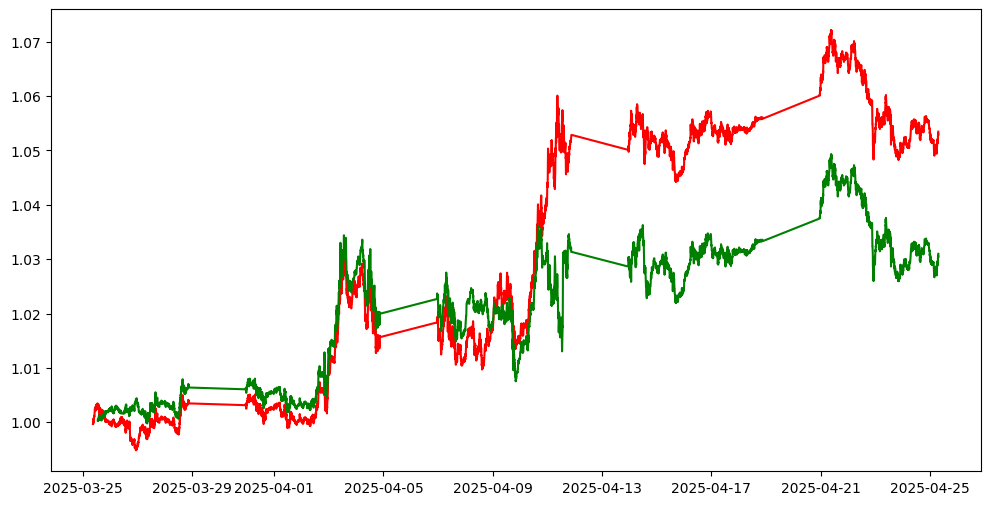

In [ ]:
data['strat_ret'] = data['pct_change'] * data['Signal'].shift(1)
cum_ret = (1+data['pct_change']).cumprod()
cum_strat_ret = (1+data['strat_ret']).cumprod()

import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.plot(cum_ret.index, cum_ret, label='Cumulative Return',color = 'red')
plt.plot(cum_strat_ret.index, cum_strat_ret, label='Cumulative Strategy Return',color = 'green')